In [1]:
import os, sys
import warnings
warnings.filterwarnings('ignore')
from IPython.display import display, Markdown, Math
import numpy as np
import pandas as pd
import networkx as nx
from scipy.stats import norm
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

# Versión local de la librería: se busca src/pmule.py subiendo desde el directorio actual
_aqui = os.path.abspath('.')
while _aqui != os.path.dirname(_aqui) and not os.path.isfile(os.path.join(_aqui, 'src', 'pmule.py')):
    _aqui = os.path.dirname(_aqui)
sys.path.append(os.path.join(_aqui, 'src'))
from pmule import (PredecessorTable, ProjectGraph, EarnedValue,
                   pinta_tikz, plot_cargas, plot_curvas_valor_ganado,
                   tanto_por_uno, ordena_rutas)

GANTT_PARAMS = dict(arrows=True)   # flechas de prelación en los diagramas de Gantt (rojas las críticas)

In [2]:
# Funciones auxiliares para mostrar los cálculos intermedios paso a paso
from itertools import combinations as _combinations


def detalle_tiempos_nodos(proyecto, duraciones):
    """Tiempos tempranos y tardíos de los nodos con los candidatos que se comparan en cada uno."""
    G = proyecto.pert_graph
    d = {data['activity']: (0 if data['activity'].startswith('@') else int(duraciones[data['activity']]))
         for _, _, data in G.edges(data=True)}
    nodos = list(proyecto.nodes)
    early, filas = {}, []
    for j in nodos:
        entrantes = [(i, data['activity']) for i, _, data in G.in_edges(j, data=True)]
        if not entrantes:
            early[j] = 0
            filas.append({'nodo': j, 'candidatos t_i + d_ij': 'nodo inicial', 'tiempo temprano = máx': 0})
            continue
        cand = {f'{a}: {early[i]} + {d[a]} = {early[i] + d[a]}': early[i] + d[a] for i, a in entrantes}
        early[j] = max(cand.values())
        filas.append({'nodo': j, 'candidatos t_i + d_ij': '; '.join(cand), 'tiempo temprano = máx': early[j]})
    tempranos = pd.DataFrame(filas).set_index('nodo')
    late, filas = {}, []
    for i in reversed(nodos):
        salientes = [(j, data['activity']) for _, j, data in G.out_edges(i, data=True)]
        if not salientes:
            late[i] = early[i]
            filas.append({'nodo': i, 'candidatos t*_j − d_ij': 'nodo final (= su tiempo temprano)', 'tiempo tardío = mín': late[i]})
            continue
        cand = {f'{a}: {late[j]} − {d[a]} = {late[j] - d[a]}': late[j] - d[a] for j, a in salientes}
        late[i] = min(cand.values())
        filas.append({'nodo': i, 'candidatos t*_j − d_ij': '; '.join(cand), 'tiempo tardío = mín': late[i]})
    tardios = pd.DataFrame(filas).set_index('nodo')
    return tempranos, tardios


def detalle_holguras(calendario, prelaciones):
    """Cómo se obtiene cada fecha y cada holgura a partir de las vecinas."""
    pred = prelaciones.immediate_predecessor
    suc = {a: sorted(s for s, ps in pred.items() if a in ps) for a in calendario.index}
    fin = int(calendario['fin_mas_temprano'].max())
    filas = []
    for a in calendario.index:
        ES, EF = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'fin_mas_temprano'])
        LS, LF = int(calendario.loc[a, 'inicio_mas_tardio']), int(calendario.loc[a, 'fin_mas_tardio'])
        dur = int(calendario.loc[a, 'duracion'])
        ps, ss = sorted(pred[a]), suc[a]
        ef_pred = {p: int(calendario.loc[p, 'fin_mas_temprano']) for p in ps}
        es_suc = {s: int(calendario.loc[s, 'inicio_mas_temprano']) for s in ss}
        lf_pred = {p: int(calendario.loc[p, 'fin_mas_tardio']) for p in ps}
        ls_suc = {s: int(calendario.loc[s, 'inicio_mas_tardio']) for s in ss}
        min_es_suc = min(es_suc.values()) if es_suc else fin
        max_lf_pred = max(lf_pred.values()) if lf_pred else 0
        filas.append({
            'actividad': a,
            'ES = máx EF pred.': (f"máx({', '.join(f'{p}: {v}' for p, v in ef_pred.items())}) = {ES}" if ps else f'inicial → {ES}'),
            'EF = ES + d': f'{ES} + {dur} = {EF}',
            'LF = mín LS suc.': (f"mín({', '.join(f'{s}: {v}' for s, v in ls_suc.items())}) = {LF}" if ss else f'final → {LF}'),
            'LS = LF − d': f'{LF} − {dur} = {LS}',
            'H_total = LS − ES': f'{LS} − {ES} = {LS - ES}',
            'H_libre = mín ES suc. − EF': f"{min_es_suc}{'' if ss else ' (fin)'} − {EF} = {min_es_suc - EF}",
            'H_indep. = máx(0, mín ES suc. − máx LF pred. − d)': f'máx(0, {min_es_suc} − {max_lf_pred} − {dur}) = {max(0, min_es_suc - max_lf_pred - dur)}',
        })
    return pd.DataFrame(filas).set_index('actividad')


def detalle_rutas(R, valores, nombre='duración', decimales=0):
    """Suma término a término de un valor (duraciones, varianzas…) a lo largo de cada ruta."""
    filas = {}
    for r in R.index:
        acts = list(R.columns[R.loc[r] == 1])
        total = float(sum(valores[a] for a in acts))
        filas[r] = {'actividades': ' - '.join(acts),
                    f'{nombre} = suma': ' + '.join(f'{a}({valores[a]:.{decimales}f})' for a in acts) + f' = {total:.{decimales}f}',
                    nombre: total}
    return pd.DataFrame(filas).T


def detalle_estimaciones(datos, a='a', m='m', b='b'):
    """Media y varianza PERT de cada actividad con los números sustituidos."""
    filas = {}
    for act, fila in datos.iterrows():
        A, M, B = float(fila[a]), float(fila[m]), float(fila[b])
        filas[act] = {'D = (a + 4m + b)/6': f'({A:g} + 4·{M:g} + {B:g})/6 = {(A + 4 * M + B) / 6:.2f}',
                      'σ² = ((b − a)/6)²': f'(({B:g} − {A:g})/6)² = {((B - A) / 6) ** 2:.3f}'}
    return pd.DataFrame(filas).T


def detalle_ackoff(proyecto, duraciones, topes, cur, pasos):
    """En cada paso de Ackoff-Sasieni: rutas críticas, opciones consideradas (actividades comunes y parejas)
    con su coste, y la elegida."""
    R = proyecto.path_matrix(dummies=False)
    d = duraciones.astype(float).copy()
    filas = []
    for paso, elegidas in sorted(pasos.items()):
        L = R @ d[R.columns]
        T = float(L.max())
        criticas = [r for r in L.index if np.isclose(L[r], T)]
        conjuntos = [set(R.columns[R.loc[r] == 1]) for r in criticas]
        con_margen = {x for x in R.columns if d[x] > topes[x] and np.isfinite(cur[x])}
        opciones = {x: float(cur[x]) for x in set.intersection(*conjuntos) & con_margen}
        if len(conjuntos) > 1:
            cand = sorted(set().union(*conjuntos) & con_margen)
            for p, q in _combinations(cand, 2):
                if all(p in s or q in s for s in conjuntos) and p not in opciones and q not in opciones:
                    opciones[f'{p}+{q}'] = float(cur[p] + cur[q])
        orden = sorted(opciones.items(), key=lambda kv: kv[1])
        filas.append({'paso': paso + 1, 'duración': int(T), 'rutas críticas': ', '.join(criticas),
                      'opciones (coste)': '; '.join(f'{k} ({v:.0f})' for k, v in orden[:6]) + (' …' if len(orden) > 6 else ''),
                      'elegida': ', '.join(elegidas), 'coste del paso': float(sum(cur[x] for x in elegidas))})
        for x in elegidas:
            d[x] -= 1
    return pd.DataFrame(filas).set_index('paso')


def detalle_valor_ganado(datos_vg, calendario, semana):
    """PV, EV y AC actividad a actividad en el punto de control."""
    filas = {}
    for a, fila in datos_vg.iterrows():
        es, dur = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'duracion'])
        frac = min(max(semana - es, 0), dur) / dur
        filas[a] = {'BAC': float(fila['BAC']), 'planificado hasta la semana': f'{min(max(semana - es, 0), dur)} de {dur}',
                    'PV = BAC·fracción': f'{fila["BAC"]:.0f}·{frac:.2f} = {fila["BAC"] * frac:.1f}',
                    'realizado (%)': int(fila['performed']),
                    'EV = BAC·%': f'{fila["BAC"]:.0f}·{fila["performed"] / 100:.2f} = {fila["BAC"] * fila["performed"] / 100:.1f}',
                    'AC': float(fila['AC']), 'PV_i': fila['BAC'] * frac, 'EV_i': fila['BAC'] * fila['performed'] / 100}
    t = pd.DataFrame(filas).T
    return t


def muestra_formula(nombre, expresion, valor, unidades=''):
    """Una línea «nombre = expresión = valor» en Markdown."""
    return Markdown(f'**{nombre}** = {expresion} = **{valor}**{(" " + unidades) if unidades else ""}')

In [3]:
%%capture
%mkdir -p ~/temp
%cd ~/temp

# Enunciado

Considere el proyecto cuyo cuadro de prelaciones, duraciones planificadas (semanas) y presupuesto por actividad (BAC, en k€) se adjunta. El coste planificado de cada actividad se reparte uniformemente a lo largo de su duración.

In [4]:
#| tbl-cap: "Planificación del proyecto"
#| label: tbl-datosEnunciado
datos_enunciado = pd.DataFrame([
#  activity, predecessor, duration, BAC
    ('A'     , '---'      , 6       , 10 ),
    ('B'     , '---'      , 5       , 50 ),
    ('C'     , 'B'        , 1       , 10 ),
    ('D'     , 'A,C'      , 1       , 50 ),
    ('E'     , 'D'        , 2       , 30 ),
    ('F'     , 'C'        , 3       , 40 ),
    ('G'     , 'E,F'      , 4       , 10 ),
    ('H'     , 'E,F'      , 8       , 50 ),
    ('I'     , 'G,H'      , 4       , 50 ),
], columns=['activity', 'predecessor', 'duration', 'BAC']).set_index('activity')
datos_enunciado

,predecessor,duration,BAC
activity,,,
A,---,6,10
B,---,5,50
C,B,1,10
D,"A,C",1,50
E,D,2,30
F,C,3,40
G,"E,F",4,10
H,"E,F",8,50
I,"G,H",4,50


Al final de la semana 10 se realiza un punto de control. Para cada actividad se anotan las semanas trabajadas hasta ese momento, el coste real incurrido (k€) y el porcentaje realizado.

In [5]:
#| tbl-cap: "Datos del punto de control (final de la semana 10)"
#| label: tbl-seguimiento
seguimiento = pd.DataFrame([
#  activity, actual_duration, AC, performed
    ('A'     , 5              , 15, 100      ),
    ('B'     , 4              , 60, 100      ),
    ('C'     , 2              , 9 , 100      ),
    ('D'     , 1              , 45, 100      ),
    ('E'     , 2              , 33, 100      ),
    ('F'     , 3              , 52, 100      ),
    ('G'     , 1              , 2 , 17       ),
    ('H'     , 1              , 3 , 6        ),
    ('I'     , 0              , 0 , 0        ),
], columns=['activity', 'actual_duration', 'AC', 'performed']).set_index('activity')
seguimiento

,actual_duration,AC,performed
activity,,,
A,5,15,100
B,4,60,100
C,2,9,100
D,1,45,100
E,2,33,100
F,3,52,100
G,1,2,17
H,1,3,6
I,0,0,0


In [6]:
pregunta_1 = "1. Dibuje los diagramas de Gantt del valor planificado y del valor ganado y calcule PV, EV, AC, CPI y SPI en el punto de control.  "
pregunta_2 = "2. Calcule la programación ganada (ES), el retraso en semanas y el índice SPI(t).  "
pregunta_3 = "3. Estime la duración final del proyecto con SPI y con SPI(t). ¿Por qué difieren? ¿Cuál es más fiable?  "
pregunta_4 = "4. ¿Qué valor tomará el SPI clásico cuando el proyecto termine, aunque acabe tarde? ¿Y el SPI(t)?  "

for item in sorted(dir()):
    if item.startswith('pregunta_'):
        display(Markdown(eval(item)))

1. Dibuje los diagramas de Gantt del valor planificado y del valor ganado y calcule PV, EV, AC, CPI y SPI en el punto de control.  

2. Calcule la programación ganada (ES), el retraso en semanas y el índice SPI(t).  

3. Estime la duración final del proyecto con SPI y con SPI(t). ¿Por qué difieren? ¿Cuál es más fiable?  

4. ¿Qué valor tomará el SPI clásico cuando el proyecto termine, aunque acabe tarde? ¿Y el SPI(t)?  

# Resolución

In [7]:
datos_proyecto = datos_enunciado.copy()
prelaciones = PredecessorTable.from_dataframe_of_strings(datos_proyecto, activity='activity', predecessor='predecessor')
proyecto = prelaciones.create_project()
BAC_total = float(datos_proyecto['BAC'].sum())
duracion_planificada = proyecto.duration(datos_proyecto['duration'])

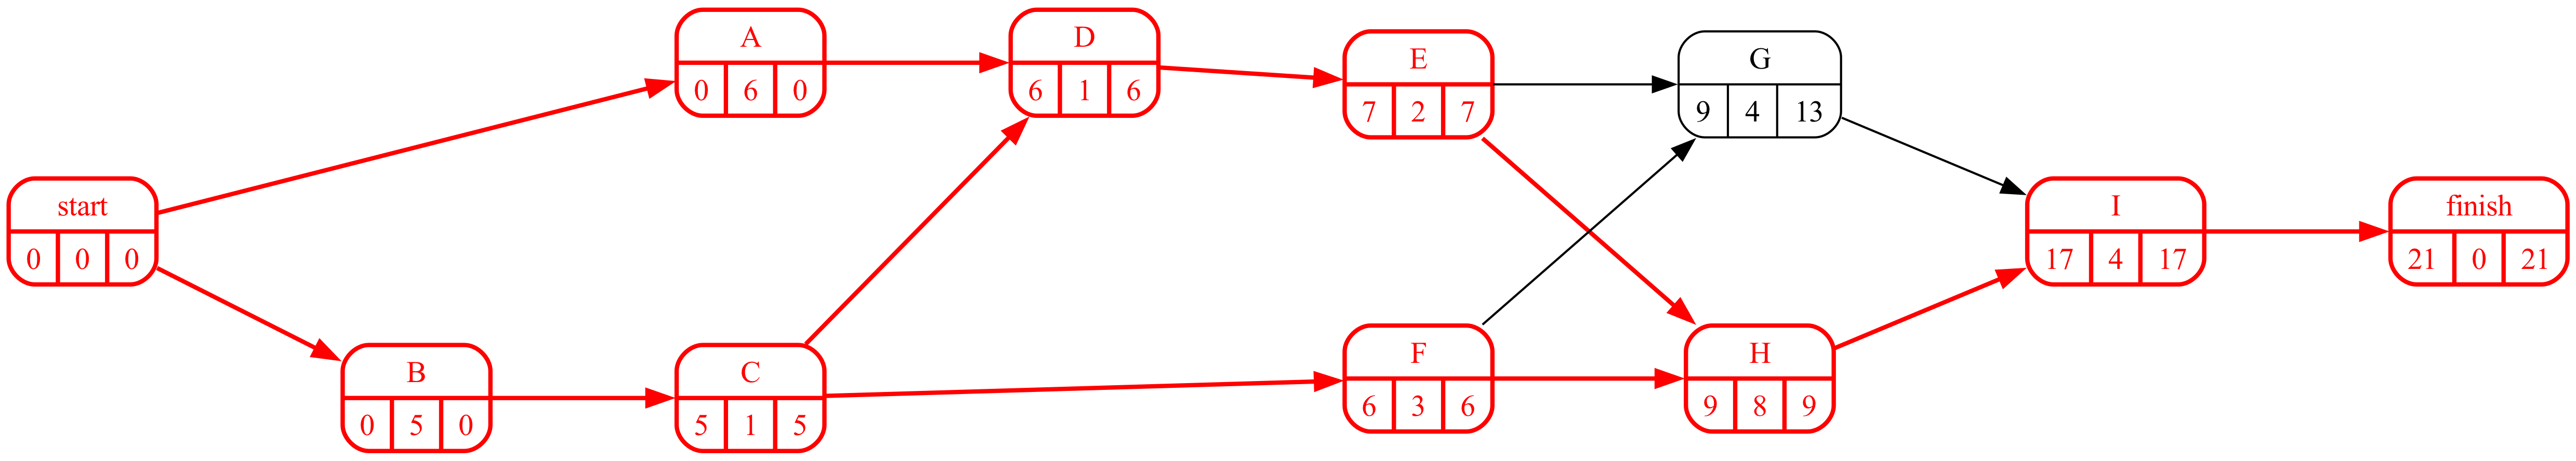

In [8]:
#| fig-cap: "Grafo Roy de la planificación"
#| label: fig-pert
proyecto.roy(durations=datos_proyecto['duration'], ranksep=1.2, nodesep=1.2)

## Apartado 1

In [9]:
display(Markdown(pregunta_1))

1. Dibuje los diagramas de Gantt del valor planificado y del valor ganado y calcule PV, EV, AC, CPI y SPI en el punto de control.  

En el Gantt del valor planificado cada casilla lleva el coste planificado de la semana (BAC / duración). En el del valor ganado, el BAC multiplicado por el porcentaje realizado se reparte entre las semanas trabajadas. En el del coste real, el coste incurrido entre las semanas trabajadas.

In [10]:
datos_valor_ganado = pd.concat([datos_proyecto, seguimiento], axis=1)
vg = EarnedValue(proyecto)
gantts = vg.calcula_gantts(datos_valor_ganado, planned_durations_label='duration',
                           actual_durations_label='actual_duration', PV_label='BAC', AC_label='AC',
                           percentage_complete_label='performed', tikz=True,
                           params=dict(period_width=1, row_height=0.7, activity_relative_height=0.6, **GANTT_PARAMS,
                                       critical_background_color='white!90!green', regular_background_color='white!90!green',
                                       regular_text_color='black', critical_text_color='black'))

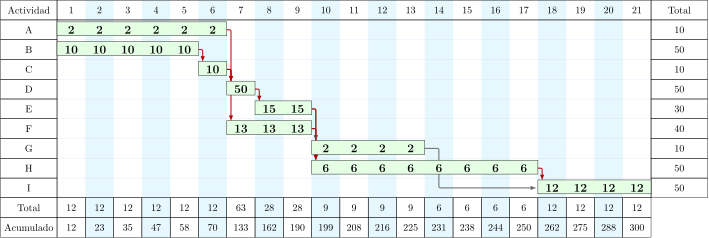

In [11]:
#| fig-cap: "PV: valor planificado"
#| label: fig-ganttPV
pinta_tikz(gantts['gantt_PV'])

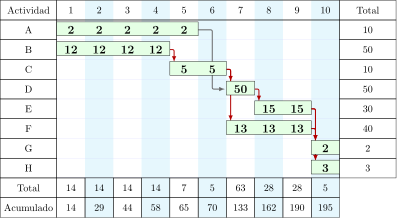

In [12]:
#| fig-cap: "EV: valor ganado"
#| label: fig-ganttEV
pinta_tikz(gantts['gantt_EV'])

In [13]:
semana_control = 10
acumulados = gantts['acumulados']
PV = float(acumulados.loc[semana_control, 'PV'])
EV = float((datos_valor_ganado['BAC'] * datos_valor_ganado['performed'] / 100).sum())
AC = float(datos_valor_ganado['AC'].sum())
CV, SV = EV - AC, EV - PV
CPI, SPI = EV / AC, EV / PV
pd.Series({'PV': PV, 'EV': EV, 'AC': AC, 'CV': CV, 'SV': SV, 'CPI': CPI, 'SPI': SPI, 'BAC': BAC_total}).round(3).to_frame('valor').T

,PV,EV,AC,CV,SV,CPI,SPI,BAC
valor,198.75,194.7,219.0,-24.3,-4.05,0.889,0.98,300.0


De dónde salen las tres cifras: el valor planificado de cada actividad es su BAC por la fracción de su duración que debería haberse ejecutado en la semana de control (según el calendario de inicios más tempranos); el valor ganado, su BAC por el porcentaje realizado; el coste real, lo gastado en ella.

In [14]:
#| tbl-cap: "PV, EV y AC actividad a actividad en el punto de control"
#| label: tbl-valorGanadoPaso
calendario_plan = proyecto.calendar(datos_proyecto['duration'])
detalle_vg = detalle_valor_ganado(datos_valor_ganado, calendario_plan, semana_control)
detalle_vg[['BAC', 'planificado hasta la semana', 'PV = BAC·fracción', 'realizado (%)', 'EV = BAC·%', 'AC']]

,BAC,planificado hasta la semana,PV = BAC·fracción,realizado (%),EV = BAC·%,AC
A,10.0,6 de 6,10·1.00 = 10.0,100,10·1.00 = 10.0,15.0
B,50.0,5 de 5,50·1.00 = 50.0,100,50·1.00 = 50.0,60.0
C,10.0,1 de 1,10·1.00 = 10.0,100,10·1.00 = 10.0,9.0
D,50.0,1 de 1,50·1.00 = 50.0,100,50·1.00 = 50.0,45.0
E,30.0,2 de 2,30·1.00 = 30.0,100,30·1.00 = 30.0,33.0
F,40.0,3 de 3,40·1.00 = 40.0,100,40·1.00 = 40.0,52.0
G,10.0,1 de 4,10·0.25 = 2.5,17,10·0.17 = 1.7,2.0
H,50.0,1 de 8,50·0.12 = 6.2,6,50·0.06 = 3.0,3.0
I,50.0,0 de 4,50·0.00 = 0.0,0,50·0.00 = 0.0,0.0


In [15]:
Markdown(f'''Sumando las columnas: PV = {detalle_vg["PV_i"].sum():.1f}, EV = {detalle_vg["EV_i"].sum():.1f}, AC = {detalle_vg["AC"].sum():.1f} k€. Y con ellas:

- CV = EV − AC = {EV:.1f} − {AC:.1f} = {CV:.1f} k€
- SV = EV − PV = {EV:.1f} − {PV:.1f} = {SV:.1f} k€
- CPI = EV / AC = {EV:.1f} / {AC:.1f} = {CPI:.3f}
- SPI = EV / PV = {EV:.1f} / {PV:.1f} = {SPI:.3f}''')

Sumando las columnas: PV = 198.8, EV = 194.7, AC = 219.0 k€. Y con ellas:

- CV = EV − AC = 194.7 − 219.0 = -24.3 k€
- SV = EV − PV = 194.7 − 198.8 = -4.1 k€
- CPI = EV / AC = 194.7 / 219.0 = 0.889
- SPI = EV / PV = 194.7 / 198.8 = 0.980

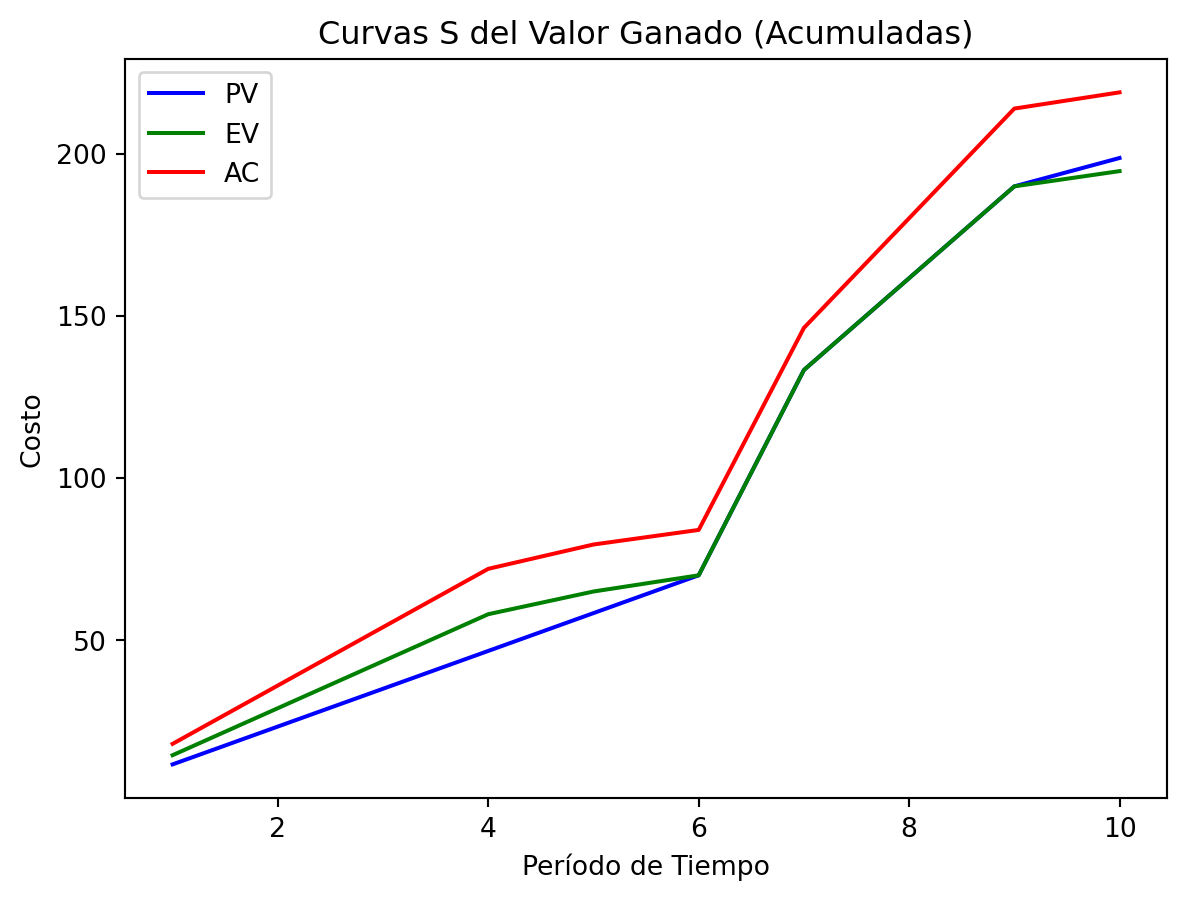

In [16]:
#| fig-cap: "Curvas S del proyecto"
#| label: fig-curvasS
plot_curvas_valor_ganado(gantts)

In [17]:
Markdown(f'''En la semana {semana_control} se ha ganado valor por {EV:.1f} k€ frente a los {PV:.1f} planificados (SV = {SV:.1f}, SPI = {SPI:.2f}: {"retraso" if SPI < 1 else "adelanto"}) y se han gastado {AC:.1f} k€ (CV = {CV:.1f}, CPI = {CPI:.2f}: por cada euro gastado se obtienen {CPI:.2f} euros de valor, {"sobrecoste" if CPI < 1 else "ahorro"}).''')

En la semana 10 se ha ganado valor por 194.7 k€ frente a los 198.8 planificados (SV = -4.1, SPI = 0.98: retraso) y se han gastado 219.0 k€ (CV = -24.3, CPI = 0.89: por cada euro gastado se obtienen 0.89 euros de valor, sobrecoste).

## Apartado 2

In [18]:
display(Markdown(pregunta_2))

2. Calcule la programación ganada (ES), el retraso en semanas y el índice SPI(t).  

La programación ganada (*Earned Schedule*) busca en qué instante de la planificación se había previsto alcanzar el valor que realmente se ha ganado:

$$ES = C + \frac{EV - PV_C}{PV_{C+1} - PV_C}$$

donde $C$ es la última semana completa con $PV_C \le EV$. Entonces $SPI(t) = ES / AT$, siendo $AT$ el tiempo real transcurrido.

In [19]:
pv_acumulado = pd.concat([pd.Series({0: 0.0}), acumulados['PV'].astype(float)])
C = int(pv_acumulado[pv_acumulado <= EV].index.max())
PV_C, PV_C1 = float(pv_acumulado[C]), float(pv_acumulado[C + 1])
AT = semana_control
ES = C + (EV - PV_C) / (PV_C1 - PV_C)
SPI_t = ES / AT
Markdown(f'PV acumulado en la semana {C}: {PV_C:.1f}; en la {C + 1}: {PV_C1:.1f}. '
         f'ES = {C} + ({EV:.1f} − {PV_C:.1f}) / ({PV_C1:.1f} − {PV_C:.1f}) = {ES:.2f} semanas. '
         f'Retraso = AT − ES = {AT - ES:.2f} semanas; SPI(t) = {ES:.2f} / {AT} = {SPI_t:.2f}.')

PV acumulado en la semana 9: 190.0; en la 10: 198.8. ES = 9 + (194.7 − 190.0) / (198.8 − 190.0) = 9.54 semanas. Retraso = AT − ES = 0.46 semanas; SPI(t) = 9.54 / 10 = 0.95.

## Apartado 3

In [20]:
display(Markdown(pregunta_3))

3. Estime la duración final del proyecto con SPI y con SPI(t). ¿Por qué difieren? ¿Cuál es más fiable?  

In [21]:
PD = duracion_planificada
IEAC_spi = PD / SPI
IEAC_t = PD / SPI_t
pd.DataFrame({'con SPI (€)': [SPI, IEAC_spi], 'con SPI(t) (tiempo)': [SPI_t, IEAC_t]},
             index=['índice', 'duración prevista (semanas)']).round(2)

,con SPI (€),con SPI(t) (tiempo)
índice,0.98,0.95
duración prevista (semanas),21.44,22.02


El SPI en unidades monetarias compara euros ganados con euros planificados, y depende de qué actividades (caras o baratas) estén retrasadas. El SPI(t) compara tiempos: cuántas semanas de avance planificado se han conseguido en las semanas transcurridas. Es más fiable para prever la duración, sobre todo en la segunda mitad del proyecto.

## Apartado 4

In [22]:
display(Markdown(pregunta_4))

4. ¿Qué valor tomará el SPI clásico cuando el proyecto termine, aunque acabe tarde? ¿Y el SPI(t)?  

In [23]:
Markdown(f'''Al terminar, EV = BAC y PV = BAC, así que el SPI clásico vale 1 aunque el proyecto haya terminado tarde: pierde su capacidad de aviso conforme avanza el proyecto. El SPI(t) al final vale PD / duración real = {PD} / duración real, que sigue siendo menor que 1 si hubo retraso.''')

Al terminar, EV = BAC y PV = BAC, así que el SPI clásico vale 1 aunque el proyecto haya terminado tarde: pierde su capacidad de aviso conforme avanza el proyecto. El SPI(t) al final vale PD / duración real = 21 / duración real, que sigue siendo menor que 1 si hubo retraso.